In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/StudentsPerformance.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
print("Dataset shape:", df.shape)

Dataset shape: (1000, 8)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [ ]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [ ]:
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nData Types:")
print(df.dtypes)


Duplicate Rows: 0

Data Types:
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object


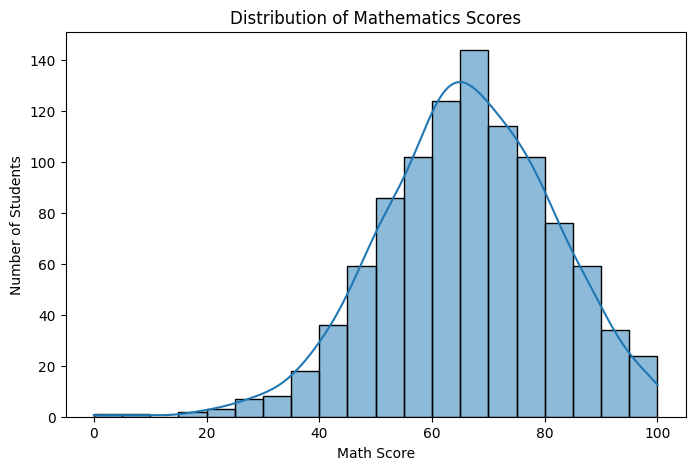

In [ ]:
# Distribution of mathematics scores
plt.figure(figsize=(8, 5))
sns.histplot(df["math score"], bins=20, kde=True)
plt.title("Distribution of Mathematics Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.show()

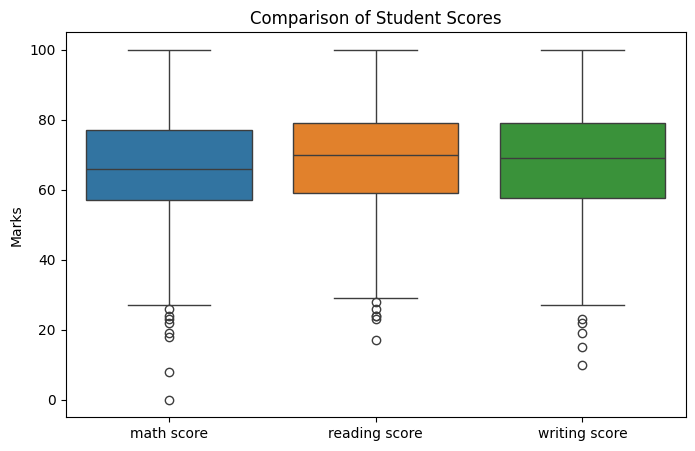

In [ ]:
# Comparison of all three scores
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[["math score", "reading score", "writing score"]])
plt.title("Comparison of Student Scores")
plt.ylabel("Marks")
plt.show()

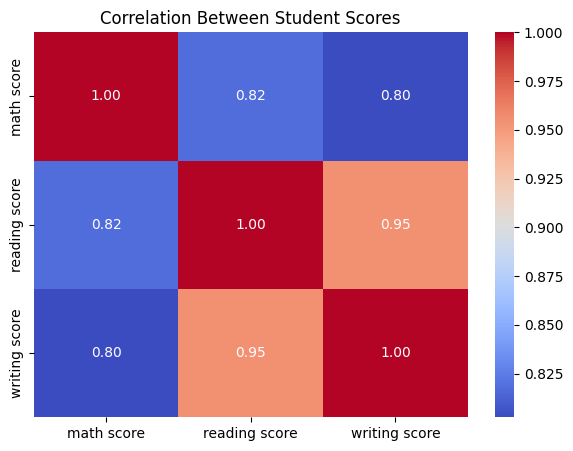

In [ ]:
# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[["math score", "reading score", "writing score"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Student Scores")
plt.show()

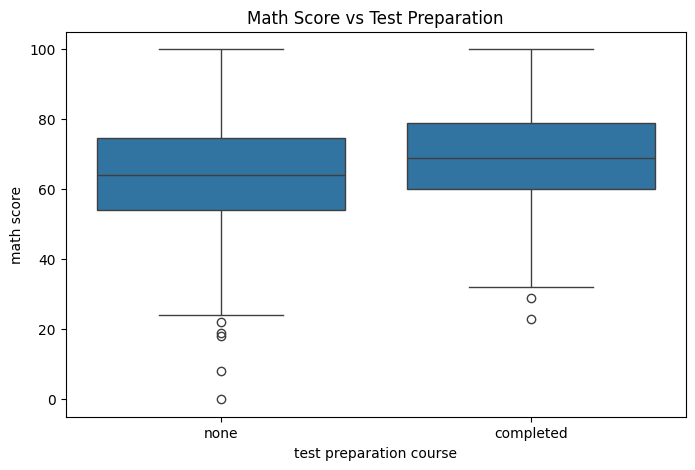

In [ ]:
# Mathematics score by test preparation status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="test preparation course", y="math score")
plt.title("Math Score vs Test Preparation")
plt.show()

In [ ]:
# Remove duplicate records if present
df = df.drop_duplicates().copy()

# Separate input features and target
X = df.drop(columns=["math score"])
y = df["math score"]

# Identify column types
categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Columns:", categorical_cols)
print("Numerical Columns:", numerical_cols)

print("\nInput Features Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())

Categorical Columns: ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
Numerical Columns: ['reading score', 'writing score']

Input Features Shape: (1000, 7)
Target Shape: (1000,)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (800, 7)
Testing Features: (200, 7)
Training Target: (800,)
Testing Target: (200,)


In [ ]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=8,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [ ]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="MAE")

print("MODEL EVALUATION RESULTS")
display(results_df.round(3))

MODEL EVALUATION RESULTS


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.215,29.095,5.394,0.880
2,Random Forest,4.655,36.428,6.036,0.850
1,Decision Tree,5.068,40.766,6.385,0.832


In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    mae_scores = -scores

    cv_results.append({
        "Model": name,
        "Mean CV MAE": mae_scores.mean(),
        "Standard Deviation": mae_scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(
    by="Mean CV MAE"
)

print("5-FOLD CROSS-VALIDATION RESULTS")
display(cv_df.round(3))

5-FOLD CROSS-VALIDATION RESULTS


,Model,Mean CV MAE,Standard Deviation
0,Linear Regression,4.342,0.190
2,Random Forest,4.831,0.263
1,Decision Tree,5.448,0.272


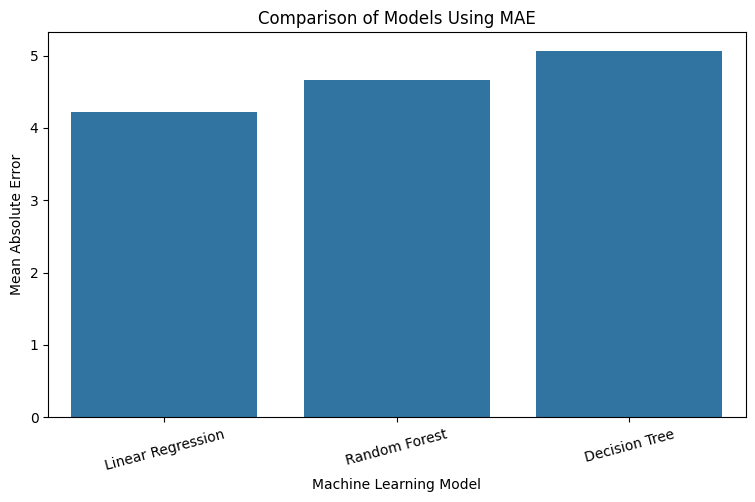

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Comparison of Models Using MAE")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Test MAE:", round(results_df.iloc[0]["MAE"], 3))
print("Test RMSE:", round(results_df.iloc[0]["RMSE"], 3))
print("Test R2 Score:", round(results_df.iloc[0]["R2 Score"], 3))

Best Model: Linear Regression
Test MAE: 4.215
Test RMSE: 5.394
Test R2 Score: 0.88


,Actual Math Score,Predicted Math Score,Prediction Error
0,91,76.39,14.61
1,53,58.89,-5.89
2,80,76.99,3.01
3,74,76.85,-2.85
4,84,87.63,-3.63
5,81,79.01,1.99
6,69,64.65,4.35
7,54,53.01,0.99
8,87,74.18,12.82
9,51,49.21,1.79


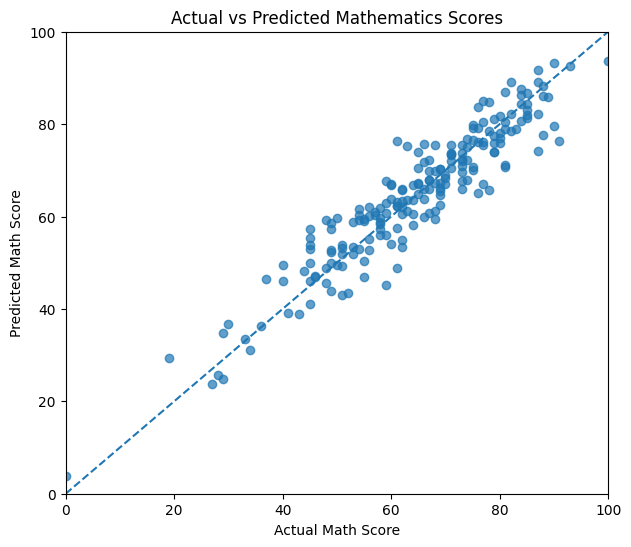

In [ ]:
y_pred_best = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Math Score": y_test.values,
    "Predicted Math Score": np.round(y_pred_best, 2)
})

comparison["Prediction Error"] = (
    comparison["Actual Math Score"]
    - comparison["Predicted Math Score"]
)

display(comparison.head(15))

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred_best, alpha=0.7)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")
plt.title("Actual vs Predicted Mathematics Scores")

plt.plot([0, 100], [0, 100], linestyle="--")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.show()

In [ ]:
# Example student details
new_student = pd.DataFrame([{
    "gender": "female",
    "race/ethnicity": "group B",
    "parental level of education": "bachelor's degree",
    "lunch": "standard",
    "test preparation course": "completed",
    "reading score": 80,
    "writing score": 85
}])

predicted_score = best_model.predict(new_student)[0]

print("Predicted Mathematics Score:", round(predicted_score, 2))

Predicted Mathematics Score: 72.67
